<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/04_water_potability_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

# Water Potability Classification with K-Nearest Neighbors

## Research question

Can laboratory-style water-quality measurements classify a sample as potable or non-potable using K-Nearest Neighbors (KNN)?

**Purpose of the analysis.** A water sample has several measured properties, but its final label is a category: potable (`1`) or non-potable (`0`). The goal is not to replace a certified water-quality decision. The goal is to learn whether a simple similarity-based machine-learning model can recognize patterns in the measurements.

This notebook is designed as a student-friendly experiment. Every major step explains what was done, why it was done, and how the output should be interpreted. KNN is especially useful for learning because it does not first learn a complicated equation; instead, it compares a new sample with nearby training samples.

## 1. Basic definitions and formulas

| Term | Simple meaning |
| --- | --- |
| Classification | Predict a category, here potable (1) or non-potable (0). |
| Feature | An input measurement used for prediction, such as pH or turbidity. |
| Target | The answer the model tries to predict, here `Potability`. |
| KNN | Predict a sample using the labels of its $k$ nearest training samples. |
| Neighbor | A training row that is close to a new row under a distance formula. |
| Euclidean distance | Straight-line distance between two scaled observations. |
| Scaling | Put features on comparable units before calculating distance. |
| Imputation | Fill missing values using information learned from training data. |
| $k$ | The number of neighboring training samples allowed to vote. |

### How KNN makes one prediction

Suppose a new water sample is being classified:

1. Compare it with every available training sample.
2. Calculate the distance from the new sample to each training sample.
3. Sort the distances from smallest to largest.
4. Keep only the closest $k$ samples.
5. Let those neighbors vote. The majority class becomes the prediction.

For example, if $k=5$ and three neighbors are potable while two are non-potable, KNN predicts potable. KNN does not create a permanent set of decision rules like a decision tree; its prediction depends on the nearby training observations.

### Euclidean distance

$$d(x,y)=\sqrt{\sum_{j=1}^{p}(x_j-y_j)^2}$$

- $x_j,y_j$ = values of feature $j$ in two water samples
- $p$ = number of features
- $d(x,y)$ = calculated distance; a smaller value means the samples are more similar according to the measured features

This notebook uses `metric="euclidean"` because the inputs are continuous laboratory measurements. Euclidean distance is intuitive: it measures the straight-line separation between two points after the features have been standardized.

### Why scaling is necessary

The variables use very different units. For example, pH may be around 5–9, while `Solids` may be tens of thousands. Without scaling, the squared difference in `Solids` could dominate the distance even if the other measurements are more informative. Standardization puts the features on a comparable scale before KNN calculates distance.

### How $k$ changes the model

- A very small $k$ makes the model sensitive to individual noisy observations. This can cause overfitting.
- A very large $k$ averages across many samples and can hide local patterns. This can cause underfitting.
- We therefore compare several values of $k$ using cross-validation rather than choosing one only because it gives a convenient result.

The notebook uses uniform voting: every selected neighbor gets one vote. This is a simple baseline and avoids allowing one unusually close observation to dominate the whole prediction.

## 2. Dataset, source, and problem statement

**Source.** [Water Potability Dataset](https://www.kaggle.com/datasets/adityakadiwal/water-potability), published by `adityakadiwal` on Kaggle. The expected file is `water_potability.csv`; download the exact version, record the access date, and place it beside this notebook, in `data/`, or in `/content/`.

The dataset contains nine laboratory-style input measurements:

- `ph`: acidity/alkalinity measurement.
- `Hardness`: dissolved calcium and magnesium characteristics.
- `Solids`: total dissolved solids.
- `Chloramines`: disinfectant-related measurement.
- `Sulfate`: sulfate concentration.
- `Conductivity`: ability of the water to conduct electricity.
- `Organic_carbon`: organic carbon measurement.
- `Trihalomethanes`: disinfection by-product measurement.
- `Turbidity`: cloudiness or suspended-particle measurement.

`Potability` is the target: `1` means potable and `0` means non-potable.

**Problem statement.** Use water-quality measurements to build an educational screening model. A positive or negative prediction is only a model output; it is not a substitute for certified laboratory analysis, regulatory limits, or public-health expertise.

**INSIGHT - 1:** This is a binary classification problem because each row belongs to one of two categories. Therefore, a confusion matrix and classification measures such as accuracy, precision, recall, specificity, F1, ROC-AUC, and PR-AUC are more appropriate than regression measures such as MAE or RMSE.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)

In [2]:
DATA_FILENAME = "water_potability.csv"
candidates = [Path(DATA_FILENAME), Path("data") / DATA_FILENAME, Path("/content") / DATA_FILENAME]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Download water_potability.csv from the cited Kaggle source and place it beside this notebook, in data/, or in /content/.")

df_raw = pd.read_csv(dataset_path)
required = {"ph", "Hardness", "Solids", "Chloramines", "Sulfate", "Conductivity", "Organic_carbon", "Trihalomethanes", "Turbidity", "Potability"}
missing = required - set(df_raw.columns)
if missing:
    raise KeyError(f"Missing required columns: {sorted(missing)}")
df_raw["Potability"] = pd.to_numeric(df_raw["Potability"], errors="coerce")
print(f"Loaded {dataset_path}: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())

Loaded data/water_potability.csv: 3,276 rows x 10 columns


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


,dtype
ph,float64
Hardness,float64
Solids,float64
Chloramines,float64
Sulfate,float64
Conductivity,float64
Organic_carbon,float64
Trihalomethanes,float64
Turbidity,float64
Potability,int64


,missing_values
Sulfate,781
ph,491
Trihalomethanes,162
Hardness,0
Chloramines,0
Solids,0
Conductivity,0
Organic_carbon,0
Turbidity,0
Potability,0


,count,percentage
Potability,,
Non-potable,1998,60.989011
Potable,1278,39.010989


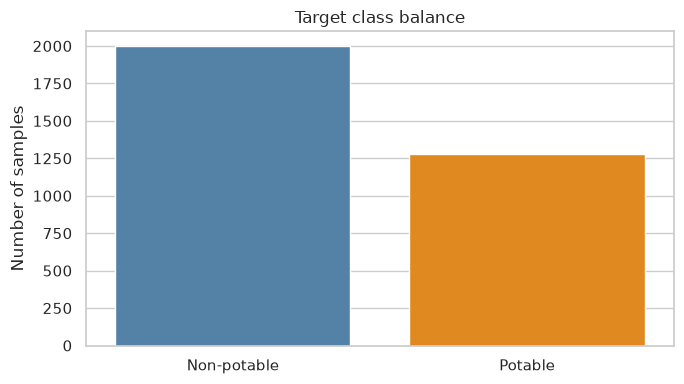

In [3]:
display(df_raw.dtypes.rename("dtype").to_frame())
display(df_raw.isna().sum().sort_values(ascending=False).rename("missing_values").to_frame())
class_summary = df_raw["Potability"].value_counts(dropna=False).sort_index().to_frame("count")
class_summary["percentage"] = class_summary["count"] / len(df_raw) * 100
display(class_summary.rename(index={0: "Non-potable", 1: "Potable"}))
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=["Non-potable", "Potable"], y=class_summary.loc[[0, 1], "count"], hue=["Non-potable", "Potable"], palette=["steelblue", "darkorange"], legend=False, ax=ax)
ax.set_title("Target class balance")
ax.set_ylabel("Number of samples")
plt.tight_layout()
plt.show()

## 3. Data cleaning and preprocessing

The cleaning decisions are intentionally conservative. We remove exact duplicate rows because repeated copies would give those observations extra voting influence. We remove rows without a usable target because a supervised model cannot learn from a row when the correct answer is unknown.

The laboratory measurements contain missing values. We do **not** fill those values before splitting the data. Instead, the KNN pipeline learns the median from the training portion and applies that learned value to validation and test rows. This prevents information from the evaluation data from influencing training.

No outliers are automatically deleted in this baseline. An unusual water measurement could be a genuine and important sample rather than a mistake. We examine distributions first and let validation performance tell us whether the simple KNN approach is being strongly affected by unusual observations.

In [4]:
df = df_raw.drop_duplicates().copy()
before = len(df_raw)
df = df.dropna(subset=["Potability"])
df = df[df["Potability"].isin([0, 1])].copy()
print(f"Exact duplicate rows removed: {before - len(df_raw.drop_duplicates()):,}")
print(f"Rows with invalid/missing target removed: {len(df_raw) - len(df):,}")
print(f"Analysis table: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
display(df.describe().T)

Exact duplicate rows removed: 0
Rows with invalid/missing target removed: 0
Analysis table: 3,276 rows x 10 columns


,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


**INSIGHT - 2:** The missing-value table tells us which laboratory measurements are incomplete. Median imputation is a reasonable robust baseline because the median is less affected by extreme values than the mean. More importantly, the imputer is inside the pipeline, so each cross-validation fold calculates its median using only that fold's training portion.

**INSIGHT - 3:** KNN does not require us to delete every unusual measurement, but it does require careful scale handling. An extreme value can make a sample appear far away from its neighbors, so the distributions and later validation results must be considered before making an aggressive outlier-removal decision.

## 4. Exploratory data analysis

EDA helps us understand the data before asking the model to make predictions. The summary table describes the center and spread of each measurement. The distribution plots show whether values are skewed, widely dispersed, or strongly overlapping between potable and non-potable samples. The correlation heatmap shows pairwise linear relationships.

These plots are not proof that a feature is useful or useless. KNN uses combined distances across all retained features, so a feature with weak individual correlation may still help when considered together with other measurements.

In [5]:
feature_cols = [c for c in df.columns if c != "Potability"]
summary = df[feature_cols].describe().T
summary["median"] = df[feature_cols].median()
summary["iqr"] = summary["75%"] - summary["25%"]
display(summary[["mean", "median", "std", "min", "25%", "50%", "75%", "max", "iqr"]])

,mean,median,std,min,25%,50%,75%,max,iqr
ph,7.080795,7.036752,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000,1.968974
Hardness,196.369496,196.967627,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000,39.816918
Solids,22014.092526,20927.833607,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008,11666.071830
Chloramines,7.122277,7.130299,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000,1.987466
Sulfate,333.775777,333.073546,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642,52.250673
Conductivity,426.205111,421.884968,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620,116.057890
Organic_carbon,14.284970,14.218338,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000,4.491850
Trihalomethanes,66.396293,66.622485,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000,21.492937
Turbidity,3.966786,3.955028,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000,1.060609


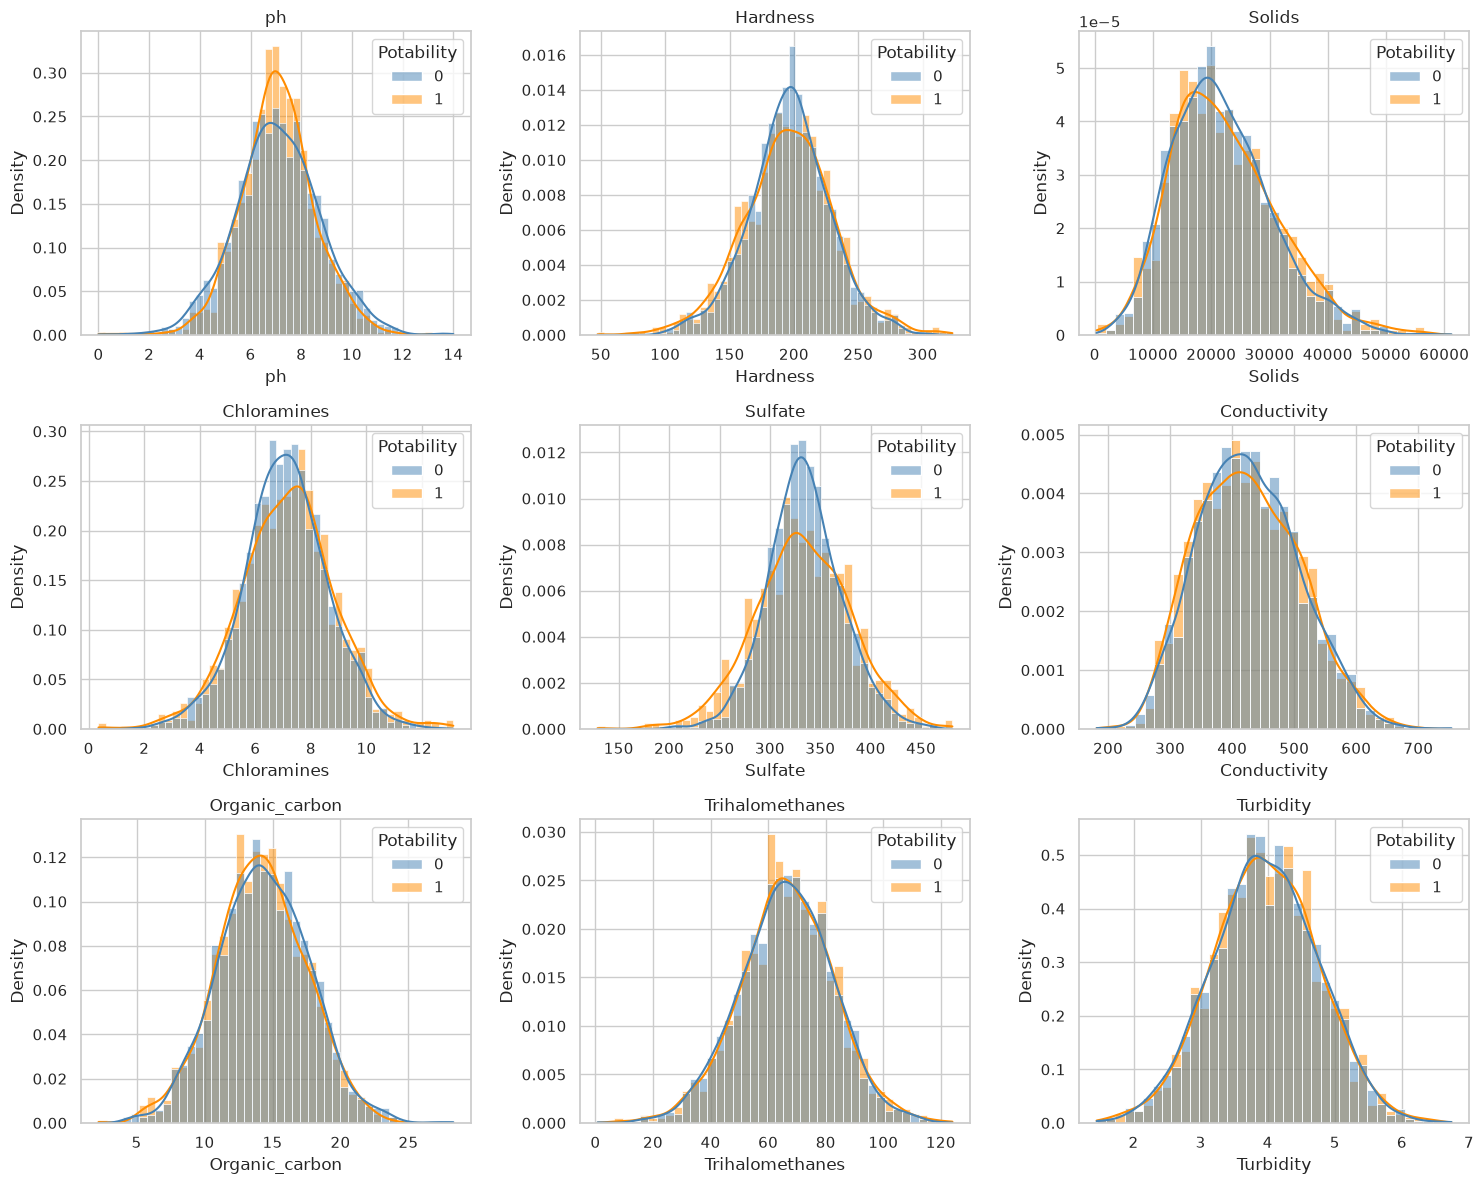

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, column in zip(axes.ravel(), feature_cols):
    sns.histplot(data=df, x=column, hue="Potability", kde=True, stat="density", common_norm=False, palette=["steelblue", "darkorange"], ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

,correlation_with_potability
Potability,1.000000
Solids,0.033743
Chloramines,0.023779
Trihalomethanes,0.007130
Turbidity,0.001581
ph,-0.003556
Conductivity,-0.008128
Hardness,-0.013837
Sulfate,-0.023577
Organic_carbon,-0.030001


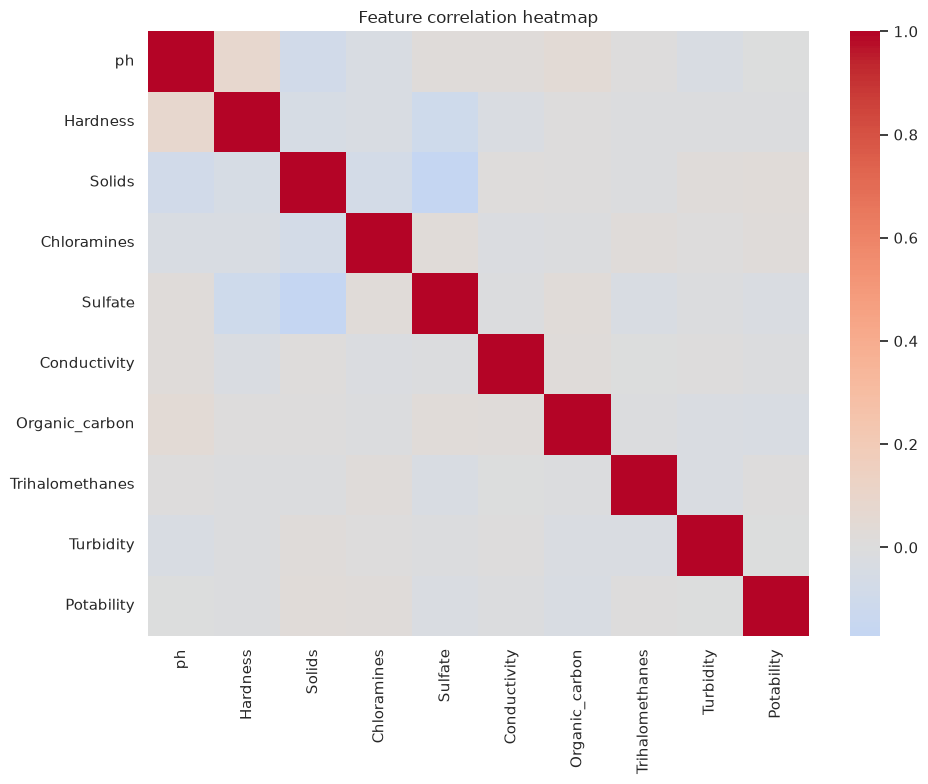

In [7]:
correlation = df.corr(numeric_only=True)
display(correlation["Potability"].sort_values(ascending=False).to_frame("correlation_with_potability"))
plt.figure(figsize=(10, 8))
sns.heatmap(correlation, cmap="coolwarm", center=0, annot=False)
plt.title("Feature correlation heatmap")
plt.tight_layout()
plt.show()

**INSIGHT - 4:** The summary statistics show why standardization is essential. A feature measured in tens of thousands can contribute much more to raw Euclidean distance than a feature measured between 0 and 10. Standardization changes the comparison to differences measured relative to each feature's own spread.

**INSIGHT - 5:** If the potable and non-potable histograms overlap substantially, a single measurement cannot cleanly separate the classes. This explains why the model must consider all nine measurements together and why perfect classification should not be expected.

**INSIGHT - 6:** Correlation describes linear association with the target and with other numeric features. A low correlation does not automatically mean a feature should be removed: KNN can still use local combinations of features that are not visible in one correlation coefficient.

## 5. Feature selection and processing

All nine laboratory measurements are retained because they represent different physical or chemical properties of the water. Removing one would need a reason supported by validation, domain knowledge, or a feature-selection experiment. `Potability` is the target and is excluded from the input features so the model cannot accidentally receive the answer as an input.

### Why use an 80/20 split?

The 80% training portion is large enough to estimate imputation values, calculate scaling parameters, compare values of $k$, and provide enough neighbors for KNN. The 20% test portion is kept aside as unseen data for one final estimate.

This ratio is a common educational baseline, not a universal law. A small dataset might benefit from repeated cross-validation, while a time-dependent problem might require a time-based split. Here, stratification is also important: it keeps the potable/non-potable proportion approximately similar in the training and test partitions.

The correct order is:

1. Split the raw rows into training and test partitions.
2. Use only training rows during cross-validation to select $k$.
3. Fit the final KNN pipeline on training data.
4. Evaluate once on the untouched test rows.

In [8]:
X = df[feature_cols].copy()
y = df["Potability"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Training rows: {len(X_train):,} ({len(X_train) / len(X):.0%})")
print(f"Testing rows: {len(X_test):,} ({len(X_test) / len(X):.0%})")
print("Distance metric: Euclidean (L2)")
print("Neighbor weighting: uniform neighbor voting")

Training rows: 2,620 (80%)
Testing rows: 656 (20%)
Distance metric: Euclidean (L2)
Neighbor weighting: uniform neighbor voting


In [9]:
def make_knn(k):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, metric="euclidean", weights="uniform")),
    ])

print("Pipeline order: training-fold median imputation -> standardization -> uniform-vote Euclidean KNN")

Pipeline order: training-fold median imputation -> standardization -> uniform-vote Euclidean KNN


**INSIGHT - 7:** Standardization changes each feature approximately to $(x-\mu)/\sigma$, where $\mu$ and $\sigma$ come from the training data. After this transformation, a one-unit difference means roughly one standard deviation for that feature. This stops `Solids` from dominating simply because its raw numbers are larger than pH.

**INSIGHT - 8:** The test partition is not used while selecting $k$. If we repeatedly chose the $k$ that performed best on the test set, the test set would stop being an honest final check and the reported score could become overly optimistic.

## 6. Model implementation and evaluation

We compare odd values of $k$ from 1 to 25 using **five-fold stratified cross-validation on the training data only**. Each fold temporarily acts as validation data while the other four folds are used for fitting. The process is repeated five times so every training observation is evaluated in a validation fold.

Balanced accuracy is the selection metric because the two classes should receive equal importance even when their counts are not exactly equal. F1 is used as a tie-break because it combines precision and recall. The final test set is not used to select $k$.

The model then reports:

- **Accuracy:** total proportion of correct predictions.
- **Precision:** among samples predicted potable, the proportion that truly are potable.
- **Recall/sensitivity:** among truly potable samples, the proportion found by the model.
- **Specificity:** among non-potable samples, the proportion correctly rejected.
- **F1 score:** balance between precision and recall.
- **ROC-AUC:** how well predicted probabilities rank the two classes across thresholds.
- **PR-AUC:** useful additional information when positive and negative classes are not perfectly balanced.

In [10]:
k_values = list(range(1, 26, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for k in k_values:
    result = cross_validate(make_knn(k), X_train, y_train, cv=cv, scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "f1": "f1", "roc_auc": "roc_auc"}, n_jobs=-1)
    cv_rows.append({"k": k, "cv_accuracy": result["test_accuracy"].mean(), "cv_balanced_accuracy": result["test_balanced_accuracy"].mean(), "cv_f1": result["test_f1"].mean(), "cv_roc_auc": result["test_roc_auc"].mean(), "cv_accuracy_std": result["test_accuracy"].std()})
cv_results = pd.DataFrame(cv_rows)
optimal_k = int(cv_results.sort_values(["cv_balanced_accuracy", "cv_f1"], ascending=False).iloc[0]["k"])
display(cv_results)
print(f"Selected k={optimal_k} using training-fold balanced-accuracy cross-validation.")

,k,cv_accuracy,cv_balanced_accuracy,cv_f1,cv_roc_auc,cv_accuracy_std
0,1,0.598473,0.574535,0.474868,0.574535,0.017137
1,3,0.614122,0.580674,0.464352,0.615704,0.019213
2,5,0.635115,0.593465,0.463456,0.629855,0.017340
3,7,0.635496,0.588107,0.443046,0.639760,0.008535
4,9,0.636260,0.583633,0.424100,0.645245,0.013793
5,11,0.631298,0.573942,0.398108,0.651680,0.015848
6,13,0.636260,0.574111,0.383644,0.654004,0.013740
7,15,0.640840,0.575410,0.375069,0.654356,0.011412
8,17,0.647328,0.578966,0.371233,0.656665,0.009835
9,19,0.651908,0.579729,0.359662,0.660023,0.013089


Selected k=5 using training-fold balanced-accuracy cross-validation.


In [11]:
knn_model = make_knn(optimal_k)
knn_model.fit(X_train, y_train)
y_pred = knn_model.predict(X_test)
y_proba = knn_model.predict_proba(X_test)[:, 1]
train_pred = knn_model.predict(X_train)
print(f"Train accuracy: {accuracy_score(y_train, train_pred):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Generalization gap: {abs(accuracy_score(y_train, train_pred) - accuracy_score(y_test, y_pred)):.2%}")

Train accuracy: 76.41%
Test accuracy: 61.43%
Generalization gap: 14.98%


In [12]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall / Sensitivity": recall_score(y_test, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp) if tn + fp else 0,
    "F1 score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
    "PR-AUC": average_precision_score(y_test, y_proba),
}, name="test_value")
display(metrics.to_frame())

,test_value
Accuracy,0.614329
Precision,0.509317
Recall / Sensitivity,0.320312
Specificity,0.802500
F1 score,0.393285
ROC-AUC,0.597817
PR-AUC,0.470172


**INSIGHT - 9:** Selecting $k$ from training-only cross-validation makes the final test metrics more trustworthy. The test score estimates how the selected workflow behaves on new samples; it is not another tuning target.

**INSIGHT - 10:** A high accuracy value must be read together with the class-specific measures. For example, a model could be correct on many non-potable samples while missing a large fraction of potable samples. Recall, specificity, precision, and the confusion matrix reveal that trade-off.

**INSIGHT - 11:** The train/test accuracy gap is a simple overfitting check. A very high training score combined with a much lower test score means the model is memorizing local training patterns rather than generalizing. A smaller gap is reassuring, although it does not guarantee that the model is useful in a new laboratory or population.

## 7. Visual diagnostics

The first visualization shows how the cross-validation scores change as $k$ changes. It helps us see whether the selected neighborhood is too small, too large, or located in a stable region. The confusion matrix gives the count of each outcome on the untouched test set. The ROC curve shows how the true-positive rate changes as the probability threshold changes.

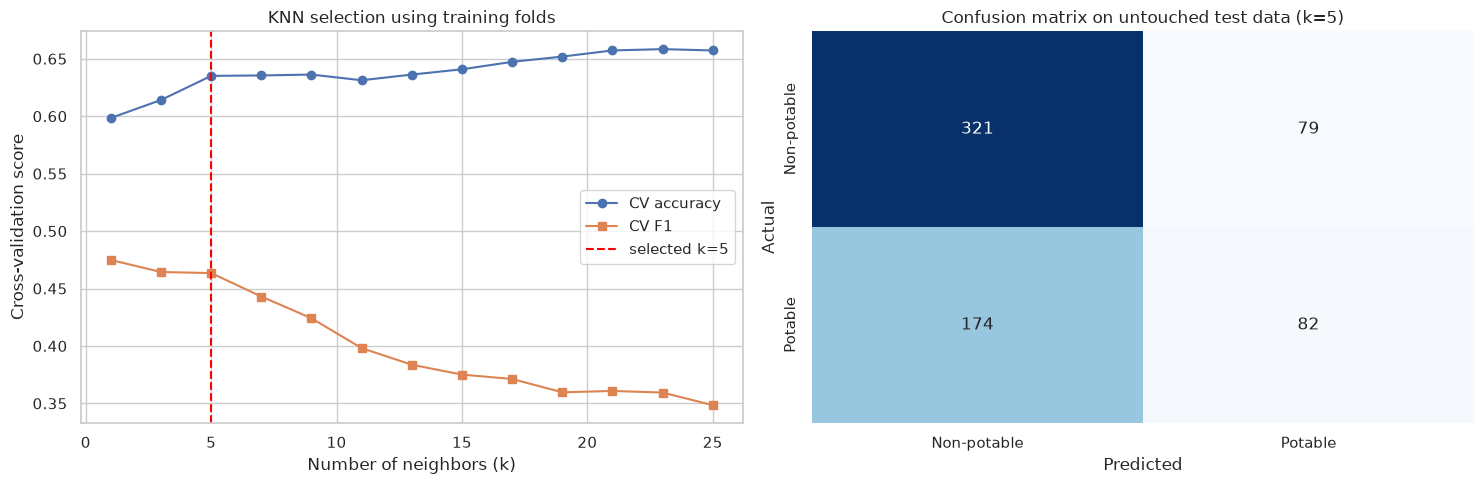

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(cv_results["k"], cv_results["cv_accuracy"], marker="o", label="CV accuracy")
axes[0].plot(cv_results["k"], cv_results["cv_f1"], marker="s", label="CV F1")
axes[0].axvline(optimal_k, color="red", linestyle="--", label=f"selected k={optimal_k}")
axes[0].set(xlabel="Number of neighbors (k)", ylabel="Cross-validation score", title="KNN selection using training folds")
axes[0].legend()
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=["Non-potable", "Potable"], yticklabels=["Non-potable", "Potable"], ax=axes[1])
axes[1].set(title=f"Confusion matrix on untouched test data (k={optimal_k})", xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()

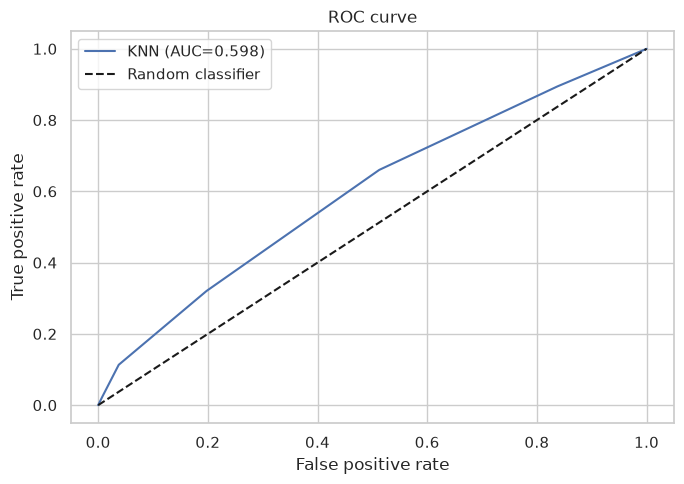

In [14]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"KNN (AUC={metrics['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

**INSIGHT - 12:** The validation curve is evidence for the selected $k$, but it is not a promise that this value will be optimal for every future dataset. A smooth region of similar scores is generally more reassuring than a single isolated peak.

**INSIGHT - 13:** The confusion matrix uses the model's default classification threshold and shows concrete counts: correct potable predictions, missed potable samples, correct non-potable predictions, and incorrectly accepted non-potable samples. ROC-AUC looks across many thresholds, so it answers a broader ranking question than the single confusion matrix.

## 8. Compare

The comparison should be made in three stages:

1. **Compare candidate $k$ values** using the cross-validation table. Prefer a value with strong balanced accuracy and F1 that is not an unstable one-fold accident.
2. **Compare training and test behavior** using the accuracy and generalization gap. If training accuracy is much higher than test accuracy, the neighborhood is too tailored to the training rows.
3. **Compare class-specific test metrics** using the confusion matrix, precision, recall, specificity, F1, ROC-AUC, and PR-AUC. The most important metric depends on the use case. A public-health screening workflow may prioritize finding as many concerning samples as possible, while a costly confirmatory workflow may also prioritize precision.

The model is not judged by accuracy alone. The selected $k$ is accepted only when its validation behavior, test behavior, and error types tell a consistent story.

## 9. Summarize

This notebook begins with a documented water-quality dataset and a clear binary target. It checks the dataset shape, data types, missing values, class balance, descriptive statistics, feature distributions, and correlations before modeling.

The preprocessing is leakage-safe: duplicate and invalid-target checks happen first, while median imputation and standardization are fitted inside the KNN pipeline. All nine laboratory measurements are retained because no feature is removed without validation evidence. The data is split into 80% training and 20% testing with stratification.

KNN uses Euclidean distance after scaling. Candidate values of $k$ are evaluated through five-fold cross-validation on training data only. The selected model is then evaluated once on the untouched test partition using accuracy, precision, recall, specificity, F1, ROC-AUC, PR-AUC, a confusion matrix, a validation curve, and an ROC curve.

## 10. Conclude

**Conclusion.** KNN is an intuitive baseline for this dataset because it predicts a water sample from the labels of similar training samples. The most important technical decisions are not arbitrary: Euclidean distance matches the continuous measurements, standardization makes the features comparable, the pipeline prevents preprocessing leakage, and training-only cross-validation prevents the test set from being used to tune $k$.

**How to explain the result.** The final test metrics describe how well this particular selected KNN workflow classified the held-out rows. They do not prove that the model is ready for real drinking-water decisions. If the confusion matrix shows many missed potable or non-potable samples, that error pattern matters more than a single headline accuracy.

**Limitations.** The dataset is a public sample and may not represent every water source. Missing values may not be missing at random. Euclidean distance treats standardized features symmetrically and may not reflect scientific importance. The target labels may also reflect a particular labeling process rather than every regulatory definition of potability. Certified laboratory testing and domain thresholds remain necessary.

**Future improvements.** Compare Euclidean with Manhattan distance, test uniform versus distance-weighted voting, use repeated or nested cross-validation, investigate domain-informed feature selection, tune the classification threshold, and evaluate on an independent dataset from a different source.